# EDA — Dynamic Concept Attention & Adversarial Crop

Notebook này đọc **trực tiếp ZIP** `adv_foa-saga-concept_n100_s300_v1(1).zip` (hoặc thư mục đã giải nén), không cần chạy lại Qwen/attack và **không cần GPU**.

**Các phần visualization:**
1. Ảnh source ban đầu và **checkpoint adversarial** theo các bước, kèm vùng crop (xanh lá) / hotspot (xanh cyan).
2. **Attention step 0** của source bằng *pixel blocks (nearest-neighbor)* và *heatmap mượt (bilinear)*, trên chính ảnh source; có heatmap riêng.
3. Attention của **target concept** (nếu có `.npz`) trên ảnh checkpoint nguồn, kèm ảnh target để đối chiếu.
4. Timeline của guide-attention qua các checkpoint và ảnh crop zoom (tùy chọn).

> **Lưu ý:** `step_00030.png`… là ảnh **adversarial checkpoint sinh từ source**, không phải một chuỗi các ảnh source độc lập. `target.npz` là *attention đối với văn bản concept target trên ảnh checkpoint nguồn/adversarial*, **không phải** attention tính từ ảnh target. Bản đồ là lưới token 14×14, không phải attention trực tiếp ở độ phân giải 224×224.

## 1. Imports và cấu hình

**Chỉ cần sửa `DATA_PATH` và `SAMPLE_ID` ở cell bên dưới**, sau đó chạy tuần tự. Trong Kaggle/Colab, thay bằng path ZIP bạn đã upload hoặc thư mục giải nén. Đọc từ ZIP nên không cần giải nén 145 MB. Dependencies: `numpy`, `Pillow`, `matplotlib` (và `pandas` nếu muốn dùng phần bảng dữ liệu).

In [44]:
from pathlib import Path
import zipfile
import io
import json
import re
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "axes.titlesize": 11, "font.size": 10})
print("EDA dependencies are ready; no GPU required.")

EDA dependencies are ready; no GPU required.


In [45]:
ROOT = Path.cwd().parent.parent
DATA_PATH = Path(str(ROOT) + "/outputs/foa+saga_attention_concept/adv_foa-saga-concept_n100_s300_v1.zip")  # ZIP OR extracted directoryDATA_PATH
DATA_PATH


WindowsPath('d:/University/Research/Graduation thesis/Experiments/Code-Adversarial-Attack-on-VLM/outputs/foa+saga_attention_concept/adv_foa-saga-concept_n100_s300_v1.zip')

In [46]:
# ================= EDIT ONLY THIS CELL TO START =================
ROOT = Path.cwd().parent.parent
DATA_PATH = Path(str(ROOT) + "/outputs/foa+saga_attention_concept/adv_foa-saga-concept_n100_s300_v1.zip")  # ZIP OR extracted directoryDATA_PATH
SAMPLE_ID = 4          # 0..99; accepts "00000" as well
STEPS_TO_SHOW = None   # None -> all available steps; e.g. [0, 30, 60, 150, 300]
ATTENTION_STEP = 0     # step for attention visualization

ATTENTION_VMAX = 0.05  # show clipped probability color range like reference image
HEATMAP_ALPHA = 0.60   # blend source image with attention colors
COLORMAP = "inferno"
SHOW_HOTSPOT = True     # cyan: hotspot/selected guide region
SHOW_ACTUAL_CROP = True  # green: actual last randomized crop; step 0: proposed initial region

SAVE_FIGURES = False
OUTPUT_DIR = Path("eda_visualizations")
# ================================================================
if SAVE_FIGURES:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(fig, name):
    if SAVE_FIGURES:
        dest = OUTPUT_DIR / name
        fig.savefig(dest, dpi=180, bbox_inches="tight")
        print("Saved:", dest.resolve())

## 2. Đọc dữ liệu (ZIP hoặc folder)

Reader dùng **lazy loading**: chỉ đọc ảnh hoặc attention của sample đang chọn. Không giải nén toàn bộ và không giữ 100 samples trong RAM.

In [47]:
class AttackDataReader:
    def __init__(self, path):
        self.root = Path(path).expanduser()
        if not self.root.exists():
            raise FileNotFoundError(
                f"DATA_PATH not found: {self.root}\n"
                "Update DATA_PATH to the ZIP file or extracted dataset directory."
            )
        self.zf = zipfile.ZipFile(self.root, "r") if self.root.is_file() and zipfile.is_zipfile(self.root) else None
        if self.zf is None and not self.root.is_dir():
            raise ValueError("DATA_PATH must be a valid .zip archive or dataset directory")
        self.members = set(self.zf.namelist()) if self.zf else None
        if not self.exists("run_config.json") or not self.exists("images/00000_source.png"):
            raise ValueError("This dataset root does not contain the expected run_config.json and images/ layout")

    def exists(self, relative_path):
        name = str(relative_path).replace("\\", "/")
        return name in self.members if self.zf is not None else (self.root / name).is_file()

    def raw(self, relative_path):
        name = str(relative_path).replace("\\", "/")
        if not self.exists(name):
            raise FileNotFoundError(f"Missing dataset file: {name}")
        return self.zf.read(name) if self.zf is not None else (self.root / name).read_bytes()

    def json(self, name):
        return json.loads(self.raw(name).decode("utf-8"))

    def jsonl(self, name):
        return [json.loads(line) for line in self.raw(name).decode("utf-8").splitlines() if line.strip()]

    def image(self, name):
        with Image.open(io.BytesIO(self.raw(name))) as im:
            return np.asarray(im.convert("RGB")).copy()

    def attention(self, sample_id, step, role="source", kind="probability"):
        if kind not in {"probability", "minmax"}:
            raise ValueError("kind must be 'probability' or 'minmax'")
        name = f"samples/{sample_id}/attention/step_{step:05d}/{role}.npz"
        if not self.exists(name):
            return None
        with np.load(io.BytesIO(self.raw(name)), allow_pickle=False) as data:
            return np.array(data[kind], dtype=np.float32, copy=True)

    def steps(self, sample_id):
        folder = f"samples/{sample_id}/checkpoints/"
        if self.zf is not None:
            paths = (n for n in self.members if n.startswith(folder))
        else:
            paths = (p.name for p in (self.root / folder).glob("step_*.png"))
        steps = set()
        for name in paths:
            match = re.search(r"step_(\d+)\.png$", str(name))
            if match:
                steps.add(int(match.group(1)))
        return sorted(steps)

    def close(self):
        if self.zf is not None:
            self.zf.close()

reader = AttackDataReader(DATA_PATH)
sid = f"{int(SAMPLE_ID):05d}"
run_config = reader.json("run_config.json")
checkpoint_steps = reader.steps(sid)
if not checkpoint_steps:
    raise ValueError(f"No checkpoints found for sample {sid}. Check SAMPLE_ID")
steps_to_show = checkpoint_steps if STEPS_TO_SHOW is None else [int(s) for s in STEPS_TO_SHOW]
unknown = sorted(set(steps_to_show) - set(checkpoint_steps))
if unknown:
    raise ValueError(f"Unavailable steps for sample {sid}: {unknown}; available: {checkpoint_steps}")
metrics_path = f"samples/{sid}/attention/checkpoint_metrics.jsonl"
geometry = {int(row["step"]): row for row in reader.jsonl(metrics_path)} if reader.exists(metrics_path) else {}
concepts_path = f"samples/{sid}/attention/concepts.json"
concepts = reader.json(concepts_path) if reader.exists(concepts_path) else {}
print(f"Source dataset: {DATA_PATH}\nSample ID: {sid}\nCheckpoint steps: {checkpoint_steps}")
print("Concepts:", json.dumps(concepts, ensure_ascii=False, indent=2))
print("Attention availability:")
for role in ("source", "guide", "target"):
    stored = [s for s in checkpoint_steps if reader.exists(f"samples/{sid}/attention/step_{s:05d}/{role}.npz")]
    print(f"  {role:>6}: {stored}")

Source dataset: d:\University\Research\Graduation thesis\Experiments\Code-Adversarial-Attack-on-VLM\outputs\foa+saga_attention_concept\adv_foa-saga-concept_n100_s300_v1.zip
Sample ID: 00004
Checkpoint steps: [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300]
Concepts: {
  "source": "Two toasters with toast on top.",
  "target": "A bathroom with two sinks and a mirror.",
  "guide": "Two toasters with toast on top."
}
Attention availability:
  source: [0, 150, 300]
   guide: [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300]
  target: [0, 150, 300]


## 3. Hàm vẽ: geometry + map

**Định dạng box quan trọng:** `hotspot`, `last_crop` là **`[top, left, height, width]` theo pixel**, còn `initial_hotspot_box` và `schedule[*].box` là **`[top, left, height, width]` chuẩn hóa [0, 1]**. Box từ step 0 chỉ là **vùng đề xuất cho các update tiếp theo**, chưa có *actual crop* ở step 0. Các step sau có crop thực tế của lần update cuối cùng trước checkpoint.

- **Xanh lá:** crop thực tế (step 0 = vùng hotspot đề xuất, vẽ nét đứt).
- **Cyan:** hotspot được chọn cho update cuối trước checkpoint.
- Cả hai nằm trong hệ tọa độ của ảnh checkpoint (ở dữ liệu này là 224×224).
- Với heatmap, `ATTENTION_VMAX=0.05` chỉ **giới hạn màu hiển thị**, không ngưỡng/lọc hay sửa đổi dữ liệu.

In [48]:
def normalized_box_to_pixels(box, image_shape):
    h, w = image_shape[:2]
    top, left, height, width = map(float, box)
    t = max(0, min(h - 1, int(top * h)))
    l = max(0, min(w - 1, int(left * w)))
    ph = max(1, int(height * h))
    pw = max(1, int(width * w))
    return (t, l, min(ph, h - t), min(pw, w - l))

def initial_region(image_shape):
    record = geometry.get(0, {})
    box = record.get("initial_hotspot_box")
    if box is None:
        filename = f"samples/{sid}/schedules/step_00000.json"
        if reader.exists(filename):
            schedule = reader.json(filename).get("schedule", [])
            if schedule:
                box = schedule[0]["box"]
    return normalized_box_to_pixels(box, image_shape) if box is not None else None

def pixel_rect(box):
    # Input is [top, left, height, width] (not x1/y1/x2/y2).
    if box is None:
        return None
    top, left, h, w = map(float, box)
    return patches.Rectangle((left, top), w, h, fill=False)

def add_rectangle(ax, box, color, label=None, linestyle="-", linewidth=1.7):
    rect = pixel_rect(box)
    if rect is not None:
        rect.set_edgecolor(color)
        rect.set_linewidth(linewidth)
        rect.set_linestyle(linestyle)
        rect.set_label(label)
        ax.add_patch(rect)

def draw_checkpoint_boxes(ax, step, image_shape, show_hotspot=True, show_crop=True):
    rec = geometry.get(step, {})
    if step == 0:
        box = initial_region(image_shape)
        if show_crop and box is not None:
            add_rectangle(ax, box, "lime", "Proposed next hotspot (not actual crop)", "--", 2.0)
    else:
        if show_hotspot and rec.get("hotspot") is not None:
            add_rectangle(ax, rec["hotspot"], "cyan", "Hotspot for last update", linewidth=1.5)
        if show_crop and rec.get("last_crop") is not None:
            add_rectangle(ax, rec["last_crop"], "lime", "Actual last crop", linewidth=2.0)

def checkpoint(step):
    return reader.image(f"samples/{sid}/checkpoints/step_{step:05d}.png")

def show_base(ax, image):
    ax.imshow(image, interpolation="nearest", extent=(0, image.shape[1], image.shape[0], 0), origin="upper")
    ax.set_xlim(0, image.shape[1])
    ax.set_ylim(image.shape[0], 0)
    ax.set_aspect("equal")
    ax.axis("off")

def show_attention(ax, image, probability, *, mode="nearest", overlay=True, vmax=None, alpha=None):
    if probability is None:
        raise ValueError("No attention map for this checkpoint/role")
    if not (probability.ndim == 2 and np.isfinite(probability).all()):
        raise ValueError("Attention map must be 2D and finite")
    h, w = image.shape[:2]
    if overlay:
        show_base(ax, image)
    im = ax.imshow(
        probability,
        extent=(0, w, h, 0), origin="upper",
        interpolation=mode, cmap=COLORMAP,
        vmin=0, vmax=ATTENTION_VMAX if vmax is None else vmax,
        alpha=(HEATMAP_ALPHA if overlay else 1.0) if alpha is None else alpha,
    )
    ax.set_xlim(0, w)
    ax.set_ylim(h, 0)
    ax.set_aspect("equal")
    ax.axis("off")
    return im

## 4. Source → adversarial qua các checkpoint, kèm ô crop

Hình này là phần tương ứng với timeline step 0, 30, 60... trong ví dụ. **Step 0** có vùng dự kiến (nét đứt). Ở các step tiếp theo, **crop xanh lá** là vùng lấy mẫu **ở lần update cuối của checkpoint đó** (không phải duy nhất cho cả 30 update).

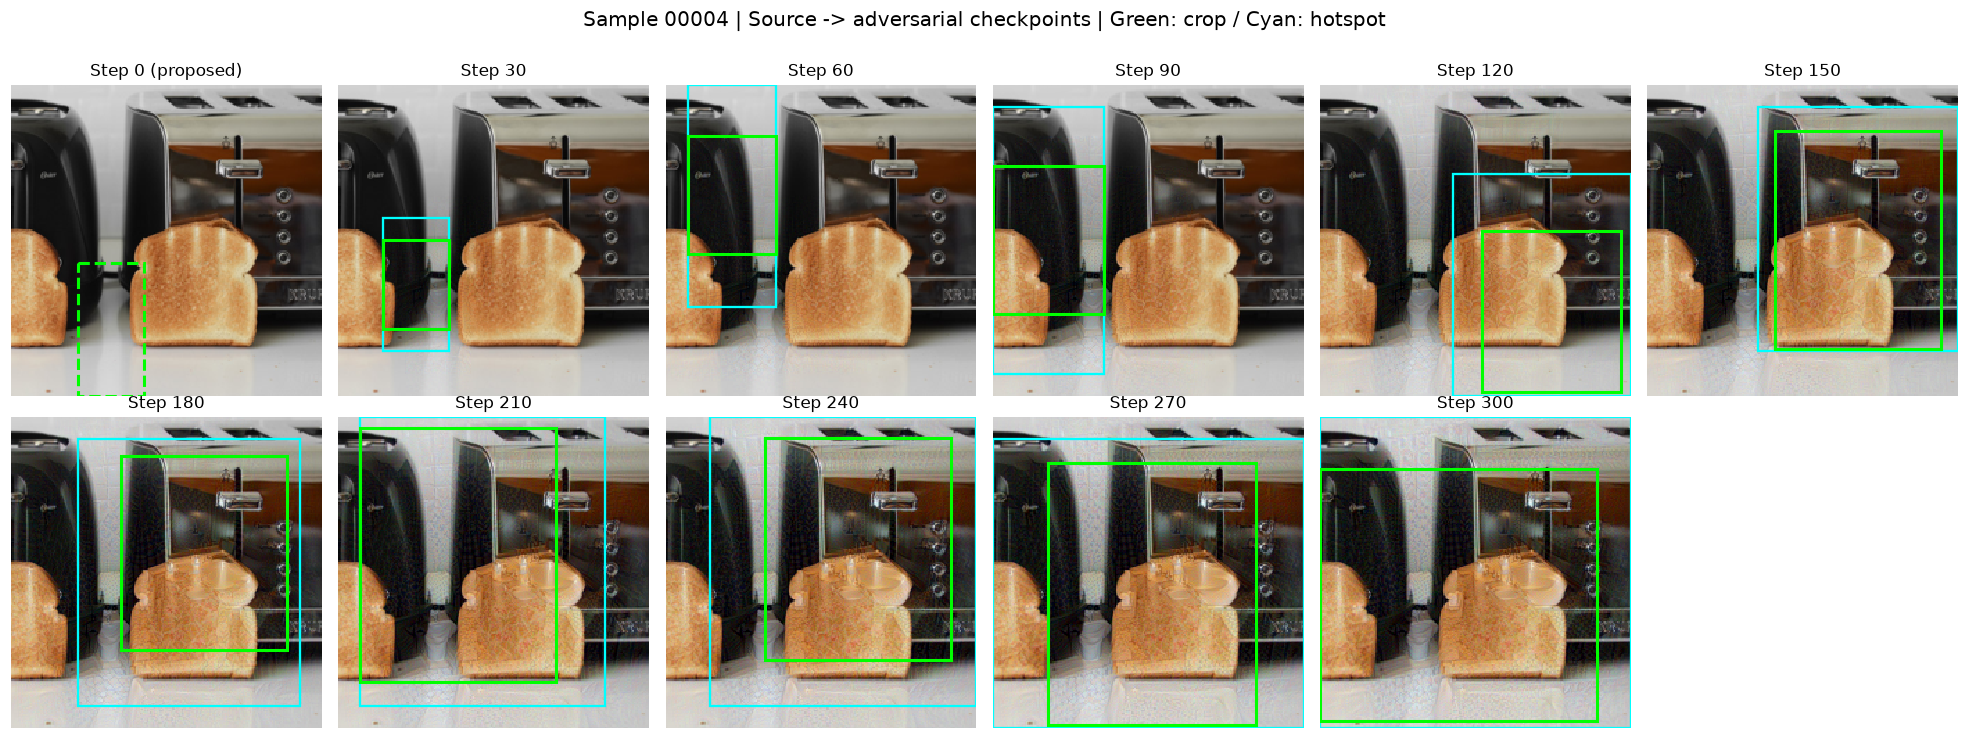

In [49]:
def plot_checkpoint_timeline(steps=None):
    steps = checkpoint_steps if steps is None else list(steps)
    ncols = min(6, len(steps))
    nrows = math.ceil(len(steps) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.0, nrows * 3.35), squeeze=False)
    for ax, step in zip(axes.flat, steps):
        img = checkpoint(step)
        show_base(ax, img)
        draw_checkpoint_boxes(ax, step, img.shape, SHOW_HOTSPOT, SHOW_ACTUAL_CROP)
        suffix = " (proposed)" if step == 0 else ""
        ax.set_title(f"Step {step}{suffix}")
    for ax in list(axes.flat)[len(steps):]:
        ax.set_visible(False)
    fig.suptitle(f"Sample {sid} | Source -> adversarial checkpoints | Green: crop / Cyan: hotspot", fontsize=13, y=1.01)
    fig.tight_layout()
    save_figure(fig, f"{sid}_source_checkpoints_with_crops.png")
    plt.show()

plot_checkpoint_timeline(steps_to_show)

## 5. Attention step 0 của source: pixel blocks & heatmap

Cả hai overlay sử dụng **`probability` gốc, chưa nội suy trong dữ liệu**. `nearest` giữ nguyên từng ô token 14×14 (pixelated); `bilinear` nội suy **chỉ cho hiển thị** (không phải bản đồ attention mới). Vùng nét đứt tại step 0 là **initial proposed hotspot**, lấy từ metadata thực tế.

Ảnh đích (target reference) không được dùng để tính source attention.

Source attention step 0: grid=(14, 14), sum=1.000000, min=4.78454e-05, max=0.0603653
Selected concept tokens: ['Two', 'asters', ' toast', ' top']


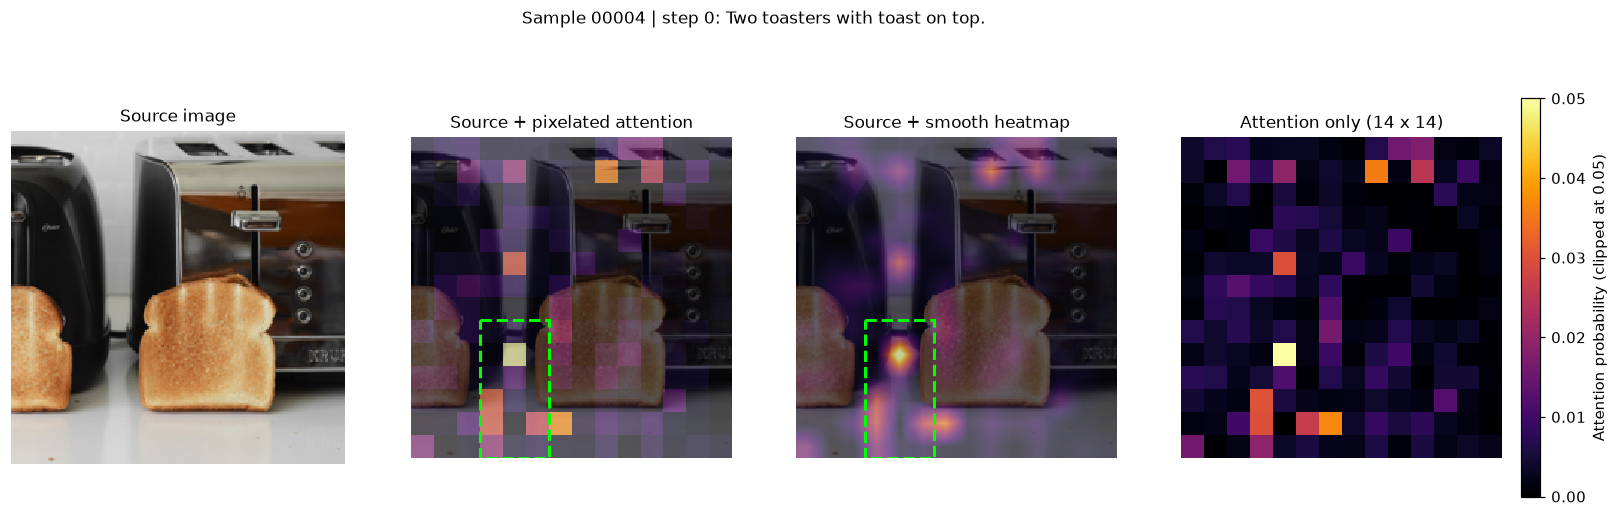

In [50]:
def plot_initial_source_attention():
    original = reader.image(f"images/{sid}_source.png")
    prob = reader.attention(sid, 0, role="source", kind="probability")
    if prob is None:
        print("Missing source.npz at step 0; skipping source attention visualization.")
        return
    metadata = f"samples/{sid}/attention/step_00000/source.json"
    detail = reader.json(metadata) if reader.exists(metadata) else {}
    print(f"Source attention step 0: grid={prob.shape}, sum={prob.sum():.6f}, "
          f"min={prob.min():.6g}, max={prob.max():.6g}")
    print("Selected concept tokens:", detail.get("selected_token_texts", "not stored"))
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.7))
    show_base(axes[0], original)
    # draw_checkpoint_boxes(axes[0], 0, original.shape, SHOW_HOTSPOT, SHOW_ACTUAL_CROP)
    axes[0].set_title("Source image")
    im1 = show_attention(axes[1], original, prob, mode="nearest")
    draw_checkpoint_boxes(axes[1], 0, original.shape, SHOW_HOTSPOT, SHOW_ACTUAL_CROP)
    axes[1].set_title("Source + pixelated attention")
    im2 = show_attention(axes[2], original, prob, mode="bilinear")
    draw_checkpoint_boxes(axes[2], 0, original.shape, SHOW_HOTSPOT, SHOW_ACTUAL_CROP)
    axes[2].set_title("Source + smooth heatmap")
    im3 = show_attention(axes[3], original, prob, mode="nearest", overlay=False)
    axes[3].set_title("Attention only (14 x 14)")
    fig.colorbar(im3, ax=list(axes)[1:], fraction=0.022, pad=0.016,
                 label=f"Attention probability (clipped at {ATTENTION_VMAX:g})")
    fig.suptitle(f"Sample {sid} | step 0: {concepts.get('source', '')}", fontsize=11, y=1.05)
    save_figure(fig, f"{sid}_source_attention_step0.png")
    plt.show()

plot_initial_source_attention()

## 6. Attention ở một checkpoint tự chọn (source / guide / target)

Đổi `ATTENTION_STEP` ở cell cấu hình và `role` dưới đây. Lưu ý **`source.npz` và `target.npz` chỉ có ở step 0, 150 và 300 trong ZIP gốc**; `guide.npz` có ở tất cả 11 checkpoint. Nếu không có map thì cell chỉ in thông báo, không tự tạo hay thay thế map.

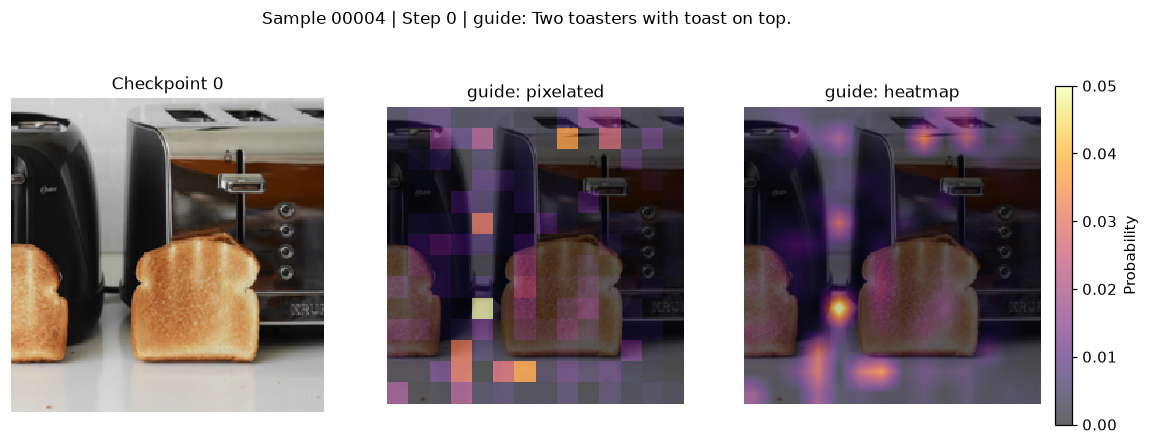

In [51]:
def plot_role_at_step(step=0, role="guide"):
    img = checkpoint(step)
    prob = reader.attention(sid, step, role)
    if prob is None:
        print(f"SKIP: No stored {role!r} map for sample {sid} at step {step}.")
        return
    fig, ax = plt.subplots(1, 3, figsize=(12.5, 4.0))
    show_base(ax[0], img)
    # draw_checkpoint_boxes(ax[0], step, img.shape, SHOW_HOTSPOT, SHOW_ACTUAL_CROP)
    ax[0].set_title(f"Checkpoint {step}")
    show_attention(ax[1], img, prob, mode="nearest")
    # draw_checkpoint_boxes(ax[1], step, img.shape, SHOW_HOTSPOT, SHOW_ACTUAL_CROP)
    ax[1].set_title(f"{role}: pixelated")
    im = show_attention(ax[2], img, prob, mode="bilinear")
    # draw_checkpoint_boxes(ax[2], step, img.shape, SHOW_HOTSPOT, SHOW_ACTUAL_CROP)
    ax[2].set_title(f"{role}: heatmap")
    fig.colorbar(im, ax=ax.ravel().tolist()[1:], fraction=0.032, pad=0.02, label="Probability")
    fig.suptitle(f"Sample {sid} | Step {step} | {role}: {concepts.get(role, '')}", y=1.05, fontsize=11)
    save_figure(fig, f"{sid}_{role}_step{step:05d}.png")
    plt.show()

plot_role_at_step(step=ATTENTION_STEP, role="guide")

## 7. Target concept attention: pixel blocks **và** smooth heatmap

- **Target reference** ở góc trái chỉ để đối chiếu nội dung. 
- Các cột còn lại đọc `target.npz` thực tế (nếu có), overlay lên **ảnh adversarial checkpoint từ source**, vì attention được tính theo **target text concept** trên ảnh checkpoint, **không tính trên target reference**.
- **Hàng 1**: `nearest` — từng ô của lưới 14×14. **Hàng 2**: `bilinear` — heatmap mượt, chỉ nội suy để hiển thị.
- Chỉ hiển thị các step có lưu dữ liệu; nếu không có `target.npz` thì bỏ qua, không tái tạo giả.

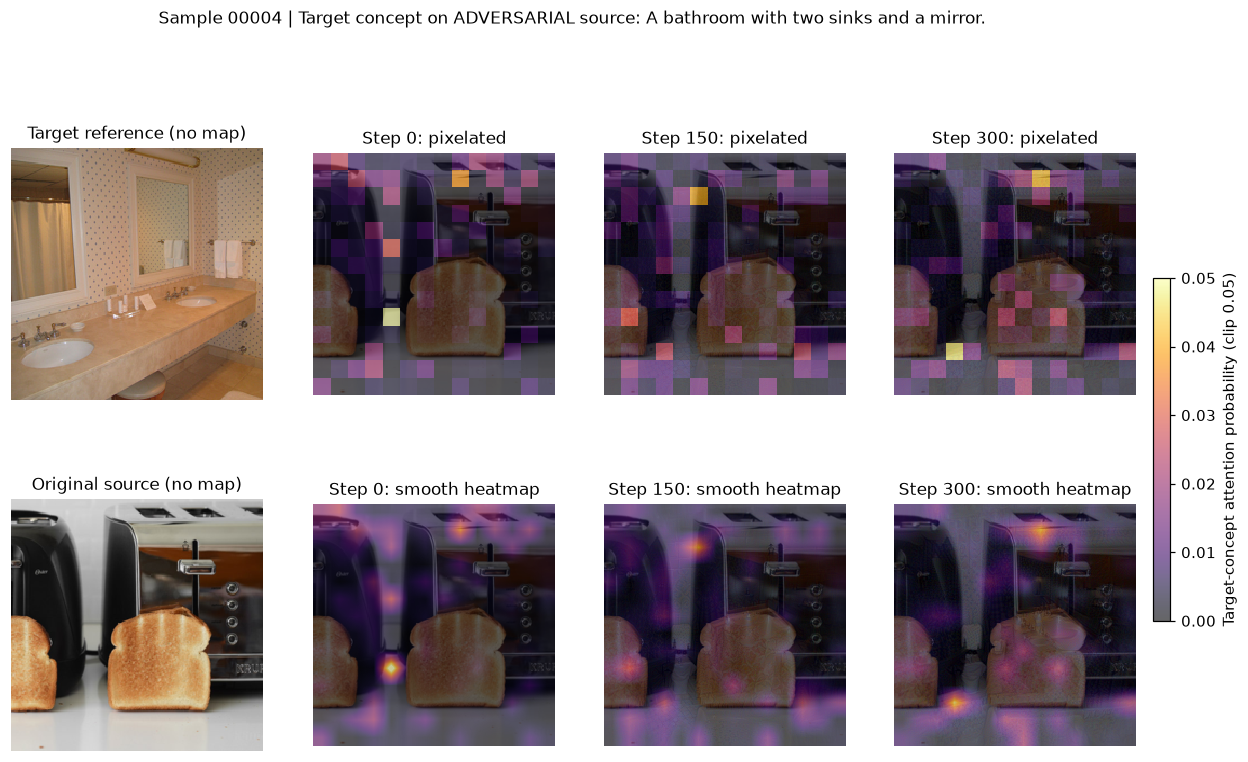

In [52]:
def plot_target_attention():
    reference_file = f"images/{sid}_target.png"
    steps = [s for s in checkpoint_steps
             if reader.exists(f"samples/{sid}/attention/step_{s:05d}/target.npz")]
    if not steps:
        print(f"SKIP: No target attention map stored for sample {sid}.")
        return
    ref = reader.image(reference_file) if reader.exists(reference_file) else None
    ncols = len(steps) + (1 if ref is not None else 0)
    fig, axs = plt.subplots(2, ncols, figsize=(max(4, ncols * 3.4), 7.6), squeeze=False)
    offset = 0
    if ref is not None:
        show_base(axs[0, 0], ref)
        axs[0, 0].set_title("Target reference (no map)")
        source_clean = reader.image(f"images/{sid}_source.png")
        show_base(axs[1, 0], source_clean)
        axs[1, 0].set_title("Original source (no map)")
        offset = 1
    im = None
    for col, step in enumerate(steps, start=offset):
        adv = checkpoint(step)
        prob = reader.attention(sid, step, "target")
        im = show_attention(axs[0, col], adv, prob, mode="nearest")
        # draw_checkpoint_boxes(axs[0, col], step, adv.shape, SHOW_HOTSPOT, SHOW_ACTUAL_CROP)

        axs[0, col].set_title(f"Step {step}: pixelated")
        show_attention(axs[1, col], adv, prob, mode="bilinear")
        # draw_checkpoint_boxes(axs[1, col], step, adv.shape, SHOW_HOTSPOT, SHOW_ACTUAL_CROP)
        axs[1, col].set_title(f"Step {step}: smooth heatmap")
    if im is not None:
        fig.colorbar(im, ax=axs[:, offset:].ravel().tolist(), fraction=0.02, pad=0.02,
                     label=f"Target-concept attention probability (clip {ATTENTION_VMAX:g})")
    fig.suptitle(f"Sample {sid} | Target concept on ADVERSARIAL source: {concepts.get('target', '')}",
                 y=1.02, fontsize=11)
    save_figure(fig, f"{sid}_target_concept_attention.png")
    plt.show()

plot_target_attention()

## 8. Guide-attention timeline: pixel overlay qua từng checkpoint

Đây là phần gần với hình mẫu: probability map được clip màu tại 0.05 và khung crop/hotspot theo step. Dùng **guide attention** vì nó được ghi ở mọi checkpoint và thật sự điều khiển vùng crop. `source` hay `target` thiếu map ở phần lớn step thì không thể có timeline đầy đủ tương tự.

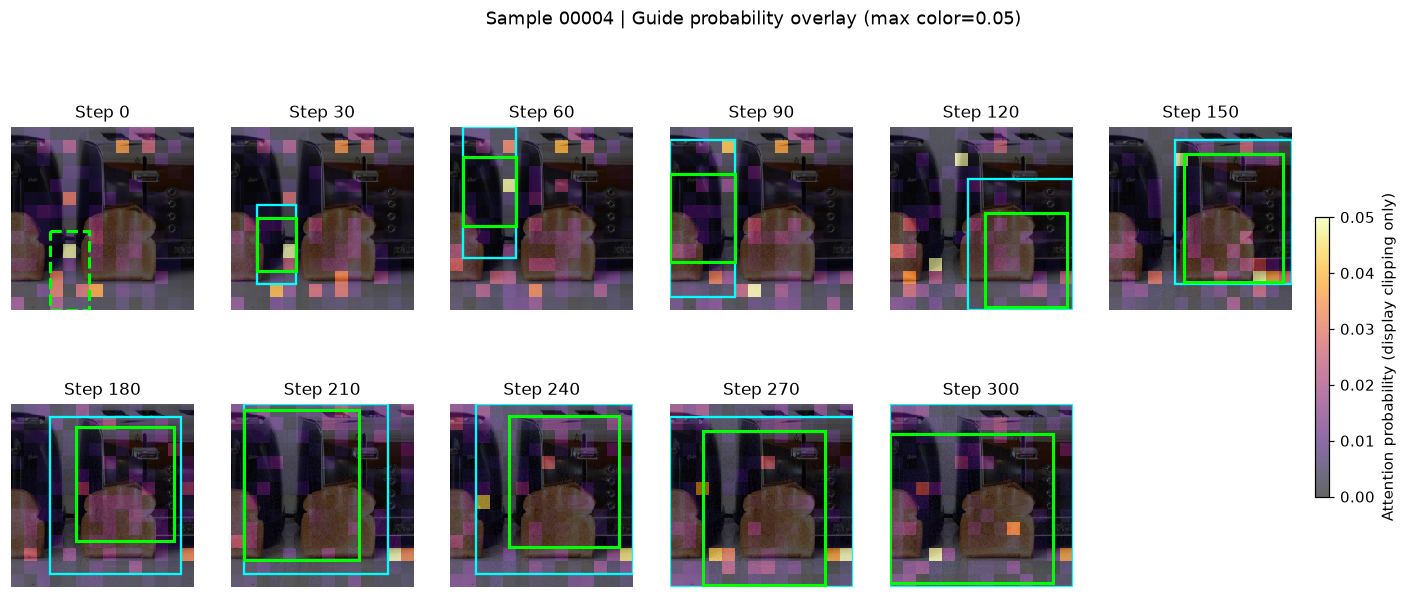

In [53]:
def plot_guide_attention_timeline(steps=None, interpolation="nearest"):
    steps = checkpoint_steps if steps is None else list(steps)
    ncols = min(6, len(steps))
    nrows = math.ceil(len(steps) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.0, nrows * 3), squeeze=False)
    heatmap_artist = None
    for ax, step in zip(axes.flat, steps):
        img = checkpoint(step)
        prob = reader.attention(sid, step, role="guide", kind="probability")
        if prob is None:
            show_base(ax, img)
            ax.set_title(f"Step {step}: map unavailable")
            continue
        heatmap_artist = show_attention(ax, img, prob, mode=interpolation)
        draw_checkpoint_boxes(ax, step, img.shape, SHOW_HOTSPOT, SHOW_ACTUAL_CROP)
        ax.set_title(f"Step {step}")
    for ax in list(axes.flat)[len(steps):]:
        ax.set_visible(False)
    fig.suptitle(f"Sample {sid} | Guide probability overlay (max color={ATTENTION_VMAX:g})", fontsize=12, y=1.02)
    if heatmap_artist is not None:
        fig.colorbar(heatmap_artist, ax=list(axes.flat)[:len(steps)], shrink=0.55, pad=0.015,
                     label="Attention probability (display clipping only)")
    save_figure(fig, f"{sid}_guide_attention_timeline.png")
    plt.show()

plot_guide_attention_timeline(steps_to_show, interpolation="nearest")

## 9. Crop zoom: xem chính xác vùng được trích từ ảnh checkpoint

Có thể đổi `CROP_DETAIL_STEP = 90`, `150`, `300`... Step 0 không có actual crop, hàm chỉ hiển thị **initial proposed hotspot** thay thế, được dán nhãn rõ.

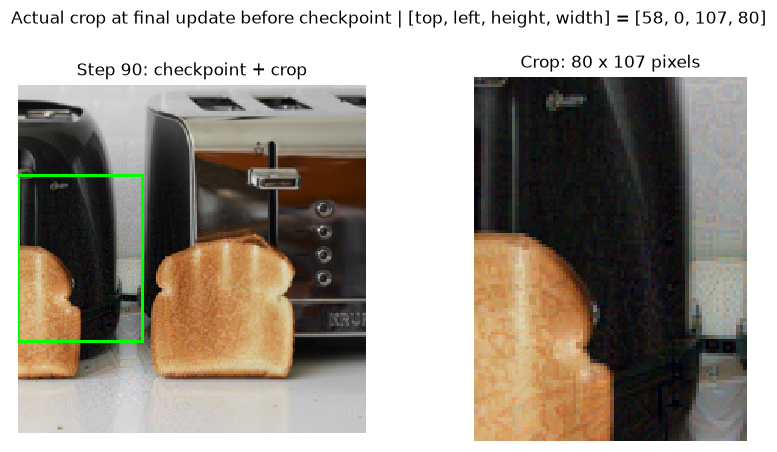

In [54]:
CROP_DETAIL_STEP = 90  # change to any stored checkpoint

def show_crop_detail(step=CROP_DETAIL_STEP):
    img = checkpoint(step)
    record = geometry.get(step, {})
    box = initial_region(img.shape) if step == 0 else record.get("last_crop")
    desc = "Proposed initial hotspot" if step == 0 else "Actual crop at final update before checkpoint"
    if box is None:
        print(f"SKIP: no available crop rectangle at step {step}.")
        return
    top, left, h, w = (int(v) for v in box)
    top, left = max(0, top), max(0, left)
    h, w = max(1, min(h, img.shape[0] - top)), max(1, min(w, img.shape[1] - left))
    extracted = img[top:top+h, left:left+w]
    fig, ax = plt.subplots(1, 2, figsize=(9, 4.3))
    show_base(ax[0], img)
    add_rectangle(ax[0], (top, left, h, w), "lime", "Selected region", linewidth=2)
    ax[0].set_title(f"Step {step}: checkpoint + crop")
    show_base(ax[1], extracted)
    ax[1].set_title(f"Crop: {w} x {h} pixels")
    fig.suptitle(f"{desc} | [top, left, height, width] = {[top,left,h,w]}", y=1.02, fontsize=11)
    save_figure(fig, f"{sid}_crop_detail_step{step:05d}.png")
    plt.show()

show_crop_detail()

## 10. Kiểm tra nguồn dữ liệu và ý nghĩa các vùng

- Các map 14×14 được lưu ở `samples/<sample_id>/attention/step_XXXXX/{source,guide,target}.npz`, key `probability` và `minmax`.
- Box crop được lưu ở `samples/<sample_id>/attention/checkpoint_metrics.jsonl`: `hotspot`, `last_crop`, `initial_hotspot_box`. Crop thật thay đổi qua **mỗi iteration**, nhưng ở checkpoint chỉ lưu **crop cuối cùng**; toàn bộ lịch sử nằm trong `trace.csv`.
- Các map source/target trong ZIP có ở step **0, 150, 300**; guide có ở step **0,30,...,300**.
- Theo implementation trong ZIP (`code/attack.py`), schedule cho update kế tiếp được tính từ **`guide['minmax']`**, không phải từ ảnh heatmap làm mượt.
- `ATTENTION_VMAX` chỉ thay đổi **cách vẽ** (clip màu); không sửa map và cũng không phản ánh threshold chọn hotspot.

### Tùy chọn: xem vùng hotspot và crop của một iteration cụ thể

Nếu muốn xem **đúng crop tại iteration 1, 2, ..., 300**, cell dưới đây đọc từ `trace.csv` thay vì dùng giá trị crop cuối mỗi checkpoint.

Update: 15 | schedule index: 1 | hotspot: [80, 64, 96, 48] | crop: [96, 64, 64, 48]
Note: This reference image may differ from the unsaved intermediate adversarial image.


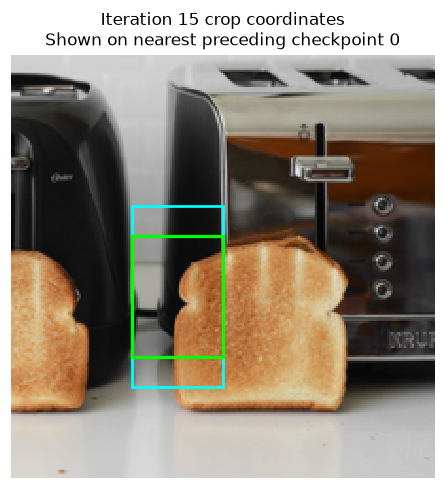

In [55]:
import csv

def inspect_iteration_crop(iteration=15):
    trace_name = f"samples/{sid}/trace.csv"
    if not reader.exists(trace_name):
        print("No trace.csv available; skipping.")
        return
    records = list(csv.DictReader(io.StringIO(reader.raw(trace_name).decode("utf-8"))))
    row = next((r for r in records if int(r["step"]) == int(iteration)), None)
    if row is None:
        print(f"Iteration {iteration} not found in trace.csv")
        return
    # trace row step denotes the completed update: crop was taken from the current adversarial state
    # BEFORE this update. Closest available image is a checkpoint, not the exact missing intermediate image.
    prior_steps = [s for s in checkpoint_steps if s <= max(0, iteration - 1)]
    reference_step = max(prior_steps) if prior_steps else checkpoint_steps[0]
    img = checkpoint(reference_step)
    crop = json.loads(row.get("crop") or "null")
    hotspot = json.loads(row.get("hotspot") or "null")
    fig, ax = plt.subplots(figsize=(5, 5))
    show_base(ax, img)
    if hotspot is not None:
        add_rectangle(ax, hotspot, "cyan", "Hotspot", linewidth=1.8)
    if crop is not None:
        add_rectangle(ax, crop, "lime", "Actual crop", linewidth=2.1)
    ax.set_title(f"Iteration {iteration} crop coordinates\nShown on nearest preceding checkpoint {reference_step}")
    print("Update:", iteration, "| schedule index:", row.get("schedule_index"),
          "| hotspot:", hotspot, "| crop:", crop)
    print("Note: This reference image may differ from the unsaved intermediate adversarial image.")
    save_figure(fig, f"{sid}_iteration{iteration:03d}_crop_on_checkpoint.png")
    plt.show()

inspect_iteration_crop(iteration=15)

### How to use

1. Đặt `DATA_PATH` trỏ tới file ZIP, ví dụ trên Colab `/content/adv_foa-saga-concept_n100_s300_v1(1).zip`, hoặc folder đã giải nén.
2. Chọn `SAMPLE_ID` và chạy **Run All**. Đổi sample rồi chạy lại từ section 2 nếu cần.
3. Muốn vẽ từng đoạn riêng: sửa `STEPS_TO_SHOW`, `ATTENTION_STEP`, `CROP_DETAIL_STEP` và chỉ chạy lại cell cần thiết.
4. Đặt `SAVE_FIGURES = True` và chạy lại các cell visualization nếu muốn lưu PNG vào `OUTPUT_DIR`.

**No attention maps are recomputed.** Notebook chỉ sử dụng đúng dữ liệu đã được ghi trong ZIP.